In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Public SDSS DR17 dataset hosted on GitHub (100,000 observations)
url = "https://raw.githubusercontent.com/dannycab/MSU_REU_ML_course/refs/heads/main/activities/data/star_classification.csv"
df = pd.read_csv(url)

print(f"Dataset shape: {df.shape}")
print("\nTarget classes:")
print(df['class'].value_counts())
df.head()

Dataset shape: (100000, 18)

Target classes:
class
GALAXY    59445
STAR      21594
QSO       18961
Name: count, dtype: int64


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.237661e+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.543777e+18,GALAXY,0.634794,5812,56354,171
1,1.237665e+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.176014e+19,GALAXY,0.779136,10445,58158,427
2,1.237661e+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.152200e+18,GALAXY,0.644195,4576,55592,299
3,1.237663e+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.030107e+19,GALAXY,0.932346,9149,58039,775
4,1.237680e+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.891865e+18,GALAXY,0.116123,6121,56187,842


In [2]:
from sklearn.model_selection import train_test_split

# Select physical astronomical features
# u, g, r, i, z = Ultraviolet, Green, Red, Near-Infrared, Infrared photometric filters
features = ['alpha', 'delta', 'u', 'g', 'r', 'i', 'z', 'redshift']
target = 'class'

# Remove rare corrupted filter readings (e.g., -9999 placeholders)
df_clean = df[df['u'] > 0].copy()

X = df_clean[features]
y = df_clean[target]

# Split into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

Training samples: 79999 | Testing samples: 20000


In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, ConfusionMatrixDisplay

# Initialize and train the model
model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

# Predict on unseen test data
y_pred = model.predict(X_test)

print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9799

Classification Report:
              precision    recall  f1-score   support

      GALAXY       0.98      0.99      0.98     11889
         QSO       0.97      0.93      0.95      3792
        STAR       0.99      1.00      1.00      4319

    accuracy                           0.98     20000
   macro avg       0.98      0.97      0.98     20000
weighted avg       0.98      0.98      0.98     20000



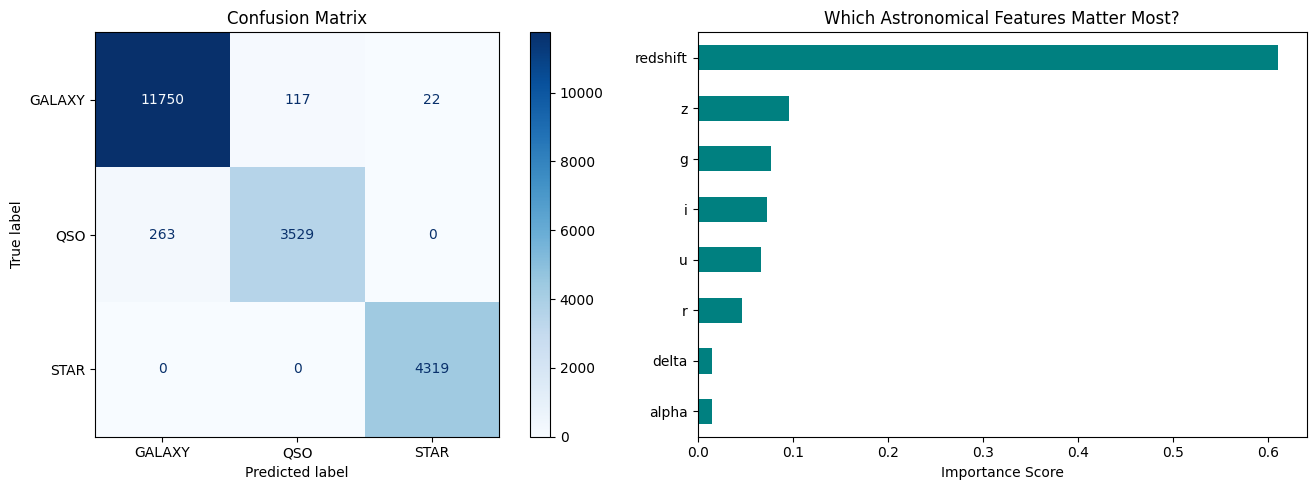

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0], cmap='Blues')
axes[0].set_title("Confusion Matrix")

# 2. Feature Importance
importances = pd.Series(model.feature_importances_, index=features).sort_values()
importances.plot(kind='barh', ax=axes[1], color='teal')
axes[1].set_title("Which Astronomical Features Matter Most?")
axes[1].set_xlabel("Importance Score")

plt.tight_layout()
plt.show()